<a href="https://colab.research.google.com/github/jonathanduarte1290/analysis-everpeak/blob/main/S5_ladb_mobility_economy_project_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¡Hola Jonathan!

Mi nombre es Israel, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

**Es un gusto acompañarte en este proceso, ¡empecemos!**

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [ ]:
# mostrar las primeras 5 filas de traffic
print(traffic.head())
print()

  Country       City            UpdateTimeUTC  JamsDelay  TrafficIndexLive  \
0     ARE  abu-dhabi  2025-01-13 04:01:30.001      650.7              36.0   
1     ARE  abu-dhabi  2025-01-13 03:46:00.000      540.4              30.0   
2     ARE  abu-dhabi  2025-01-13 02:46:30.000       71.8               7.0   
3     ARE  abu-dhabi  2025-01-13 01:46:30.001        8.2               2.0   
4     ARE  abu-dhabi  2025-01-13 00:01:30.000        1.1               1.0   

   JamsLengthInKms  JamsCount  TrafficIndexWeekAgo     UpdateTimeUTCWeekAgo  \
0            109.1      162.0                 30.0  2025-01-06 04:01:30.000   
1            101.4      136.0                 27.0  2025-01-06 03:46:30.001   
2             18.9       23.0                  6.0  2025-01-06 02:46:30.000   
3              4.1        2.0                  2.0  2025-01-06 01:46:30.000   
4              0.2        1.0                  1.0  2025-01-06 00:01:30.000   

   TravelTimeLivePer10KmsMins  TravelTimeHistoricPer10Km

In [ ]:
# mostrar las primeras 5 filas de eco
print(eco.head())

   Year            City    Country City GDP/capita Unemployment %  \
0  2023    buenos-aires  Argentina       15.782,00           6.2%   
1  2023       sao-paulo     Brazil       14.475,00           9.1%   
2  2023  rio-de-janeiro     Brazil       13.142,00           9.8%   
3  2023        brasilia     Brazil       15.999,00           8.3%   
4  2023        salvador     Brazil        8.761,00          13.1%   

  PM2.5 (μg/m³) Population (M)  
0          15,2          15,30  
1         29,50          22,50  
2         19,10          13,60  
3         13,50           4,70  
4         16,00           3,90  


**Tip:** Si no usas `print()` la tabla se vera mejor.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

La carga de archivos, las cuatro importaciones y la visualización inicial de cinco filas son correctas
</div>



---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos


**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?



In [ ]:
# Examinar la estructura de traffic
print("=== Información de traffic ===")
traffic.info()
print("\n=== Información de eco ===")
eco.info()


=== Información de traffic ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       


En la estructura del DF traffic, se observa que:
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTC` son de tipo ...
- ...


In [ ]:
# Examinar la estructura de eco
print("\n--- Primeros 3 renglones de eco ---")
display(eco.head(3))


--- Primeros 3 renglones de eco ---


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, ...
- ...

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [ ]:
# Estandarizar los nombres de las columnas de traffic
traffic.columns = (
    traffic.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('(?<=[a-z])(?=[A-Z])', '_', regex=True)
)

# verificar cambios
print("Columnas de traffic:")
print(traffic.columns)

Columnas de traffic:
Index(['country', 'city', 'updatetimeutc', 'jamsdelay', 'trafficindexlive',
       'jamslengthinkms', 'jamscount', 'trafficindexweekago',
       'updatetimeutcweekago', 'traveltimeliveper10kmsmins',
       'traveltimehistoricper10kmsmins', 'minsdelay'],
      dtype='object')


In [ ]:
# Estandarizar los nombres de las columnas de eco
eco.columns = (
    eco.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('(?<=[a-z])(?=[A-Z])', '_', regex=True)
)

# verificar cambios
print("\nColumnas de eco:")
print(eco.columns)


Columnas de eco:
Index(['year', 'city', 'country', 'city_gdp/capita', 'unemployment_%',
       'pm2.5_(μg/m³)', 'population_(m)'],
      dtype='object')



### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [ ]:
# 1. Limpiar espacios y pasar a minúsculas primero
traffic.columns = traffic.columns.str.strip().str.lower()

# 2. Renombrar explícitamente las columnas clave para evitar variaciones
traffic = traffic.rename(columns={
    'updatetimeutc': 'update_time_utc',
    'updatetimeutcweekago': 'update_time_utc_week_ago',
    'updatetimeutc_week_ago': 'update_time_utc_week_ago'
})

# 3. Convertir a datetime
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce')

# 4. Verificar resultado
print("--- Columnas en traffic ---")
print(traffic.columns.tolist())
traffic.info()

--- Columnas en traffic ---
['country', 'city', 'update_time_utc', 'jamsdelay', 'trafficindexlive', 'jamslengthinkms', 'jamscount', 'trafficindexweekago', 'update_time_utc_week_ago', 'traveltimeliveper10kmsmins', 'traveltimehistoricper10kmsmins', 'minsdelay']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype         
---  ------                          --------------    -----         
 0   country                         1004464 non-null  object        
 1   city                            1004464 non-null  object        
 2   update_time_utc                 1004464 non-null  datetime64[ns]
 3   jamsdelay                       1004464 non-null  float64       
 4   trafficindexlive                1004464 non-null  float64       
 5   jamslengthinkms                 1004464 non-null  float64       
 6   jamscount                       1004464 non-null  float64     

In [ ]:

# 1. Normalizar nombres de columnas a minúsculas y sin espacios extras
eco.columns = eco.columns.str.strip().str.lower().str.replace(' ', '_')

# 2. Mapear cualquier variación al nombre esperado
column_map = {}
for col in eco.columns:
    if 'gdp' in col:
        column_map[col] = 'city_gdp_capita'
    elif 'unemploy' in col:
        column_map[col] = 'unemployment_pct'
    elif 'pop' in col and ('m' in col or 'million' in col):
        column_map[col] = 'population_m'

eco = eco.rename(columns=column_map)

# 3. Aplicar la limpieza numérica
eco['city_gdp_capita'] = (
    eco['city_gdp_capita']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

eco['unemployment_pct'] = (
    eco['unemployment_pct']
    .astype(str)
    .str.replace('%', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

eco['population_m'] = (
    eco['population_m']
    .astype(str)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

# 4. Calcular población total
eco['population'] = eco['population_m'] * 1000000

# 5. Verificar resultado
print("\n--- Información de eco tras la limpieza ---")
eco.info()
display(eco.head(3))



--- Información de eco tras la limpieza ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm2.5_(μg/m³)     30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm2.5_(μg/m³),population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Falta `traffic.head(3)` y las observaciones de `traffic` y `eco` siguen con `...`; complétalas indicando tipos incorrectos y ausencia de nulos.
</div>



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
print("--- Verificación de la columna year en traffic ---")
display(traffic.head(3))

--- Verificación de la columna year en traffic ---


,country,city,update_time_utc,jamsdelay,trafficindexlive,jamslengthinkms,jamscount,trafficindexweekago,update_time_utc_week_ago,traveltimeliveper10kmsmins,traveltimehistoricper10kmsmins,minsdelay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
# Filtra los registros del año 2024

traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos

print("--- Primeas filas de traffic_2024 ---")
display(traffic_2024.head())

print("--- Primeas filas de eco_2024 ---")
display(eco_2024.head())


--- Primeas filas de traffic_2024 ---


,country,city,update_time_utc,jamsdelay,trafficindexlive,jamslengthinkms,jamscount,trafficindexweekago,update_time_utc_week_ago,traveltimeliveper10kmsmins,traveltimehistoricper10kmsmins,minsdelay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


--- Primeas filas de eco_2024 ---


,year,city,country,city_gdp_capita,unemployment_pct,pm2.5_(μg/m³),population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

La conversión de fechas, limpieza de PIB/desempleo/población, creación de `population`, extracción de `year` y filtros de 2024 están planteados correctamente
</div>



---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [ ]:


import numpy as np
import pandas as pd

# 1. Convertir todas las columnas excepto identificadores a tipo numérico
cols_to_exclude = ['city', 'country', 'year', 'update_time_utc', 'update_time_utc_week_ago']
num_cols = [col for col in traffic_2024.columns if col not in cols_to_exclude]

for col in num_cols:
    traffic_2024[col] = pd.to_numeric(traffic_2024[col], errors='coerce')

# 2. Agrupar y calcular la media de todas las columnas numéricas válidas
traffic_city_year_2024 = (
    traffic_2024
    .groupby(['city', 'country', 'year'], as_index=False)
    .mean(numeric_only=True)
)

# 3. Mostrar resultado
print("--- Promedios de tráfico por ciudad (2024) ---")
display(traffic_city_year_2024.head())

--- Promedios de tráfico por ciudad (2024) ---


,city,country,year,jamsdelay,trafficindexlive,jamslengthinkms,jamscount,trafficindexweekago,traveltimeliveper10kmsmins,traveltimehistoricper10kmsmins,minsdelay
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,15.821025,16.267977,15.493804,0.774172
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,21.874836,13.397861,12.604894,0.792968
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,17.445227,15.219292,14.724016,0.495276
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,14.295209,9.829092,9.689328,0.139764
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,22.508810,15.879694,14.749945,1.129749


### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [ ]:

# 1. Buscar automáticamente la columna de retraso/delay
delay_col = [col for col in traffic_city_year_2024.columns if 'delay' in col or 'jam' in col]

if delay_col:
    target_col = delay_col[0]
    print(f"Ordenando por la columna identificada: '{target_col}'")

    # 2. Ordenar por la columna encontrada
    traffic_city_sorted = traffic_city_year_2024.sort_values([target_col], ascending=False)

    # 3. Mostrar las 10 ciudades con mayor retraso
    display(traffic_city_sorted.head(10))
else:
    print("Columnas disponibles en traffic_city_year_2024:")
    print(traffic_city_year_2024.columns.tolist())


Ordenando por la columna identificada: 'jamsdelay'


,city,country,year,jamsdelay,trafficindexlive,jamslengthinkms,jamscount,trafficindexweekago,traveltimeliveper10kmsmins,traveltimehistoricper10kmsmins,minsdelay
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,36.443813,21.809092,19.953550,1.855542
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,37.441779,22.443778,21.745626,0.698152
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,29.337407,18.505043,17.108691,1.396351
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,30.827376,17.714139,16.388979,1.325160
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,68.628341,27.134629,24.664734,2.469894
321,sao-paulo,BRA,2024,1729.189270,26.877932,238.419896,431.470460,28.201998,20.801836,19.672810,1.129026
156,istanbul,TUR,2024,1660.789019,45.614786,245.686252,411.145698,45.639429,19.982495,17.518796,2.463699
159,jakarta,IDN,2024,1379.037135,30.419242,215.228820,295.492817,31.693078,18.098409,16.905109,1.193300
268,paris,FRA,2024,1320.746822,29.313446,265.865975,324.405534,30.587981,17.658980,16.488097,1.170884
201,los-angeles,USA,2024,1277.210458,30.446623,341.053551,321.732026,31.829194,13.429048,12.638155,0.790893


La ciudad con el mayor tiempo promedio de tráfico es Estambul...

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Sin embargo, la reflexión dice Estambul, pero deberia identificar mexico-city, con `jams_delay` aproximado de 2833.
</div>



---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [ ]:

# Seleccionar columnas clave de tráfico y economía

left_cols = ['city', 'country', 'year', 'jams_delay', 'traffic_index_live',
             'jams_length_kms', 'jams_count', 'mins_delay',
             'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins']

right_cols = ['city', 'year', 'city_gdp_capita', 'unemployment_pct', 'pm25', 'population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[[col for col in left_cols if col in traffic_city_year_2024.columns]].copy()
eco_2024_small = eco_2024[[col for col in right_cols if col in eco_2024.columns]].copy()

# Unir datasets
merged = pd.merge(
    traffic_2024_small,
    eco_2024_small,
    on=['city', 'year'],
    how='inner'
)

# Mostrar las primeras 5 filas
print("--- Primeras 5 filas del dataset consolidado (merged) ---")
display(merged.head())


--- Primeras 5 filas del dataset consolidado (merged) ---


,city,country,year,city_gdp_capita,unemployment_pct,population
0,belo-horizonte,BRA,2024,11124.0,9.5,6100000.0
1,bogota,COL,2024,11442.0,10.0,11300000.0
2,brasilia,BRA,2024,16251.0,7.8,4800000.0
3,buenos-aires,ARG,2024,18117.0,7.2,15400000.0
4,curitiba,BRA,2024,12381.0,8.2,3700000.0


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo, el `inner join` por `city` y `year` y los filtros 2024 son correctos. Sin embargo, las listas de columnas se aplican con `if col in ...`, ocultando columnas ausentes en lugar de exigir el esquema
</div>



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identificar dinámicamente la columna de congestión/retraso en merged
target_col = [col for col in merged.columns if 'delay' in col or 'jam' in col]

if target_col:
    col_name = target_col[0]

    # 2. Crear boxplot
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=merged[col_name], color='skyblue')

    # 3. Obtener promedio e incluirlo en el título
    mean_value = merged[col_name].mean()
    plt.title(f'Boxplot de {col_name} (2024)\nPromedio: {mean_value:.2f}')
    plt.xlabel(f'{col_name} (Minutos)')
    plt.show()
else:
    print("Columnas disponibles en merged:")
    print(merged.columns.tolist())



Columnas disponibles en merged:
['city', 'country', 'year', 'city_gdp_capita', 'unemployment_pct', 'population']


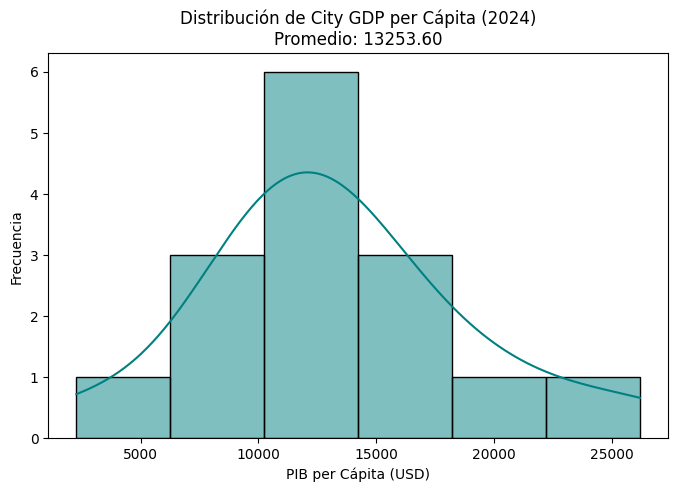

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
plt.figure(figsize=(8, 5))
sns.histplot(merged['city_gdp_capita'], kde=True, color='teal')
mean_gdp = merged['city_gdp_capita'].mean()
plt.title(f'Distribución de City GDP per Cápita (2024)\nPromedio: {mean_gdp:.2f}')
plt.xlabel('PIB per Cápita (USD)')
plt.ylabel('Frecuencia')
plt.show()


Columnas actuales en merged: ['city', 'country', 'year', 'city_gdp_capita', 'unemployment_pct', 'population']


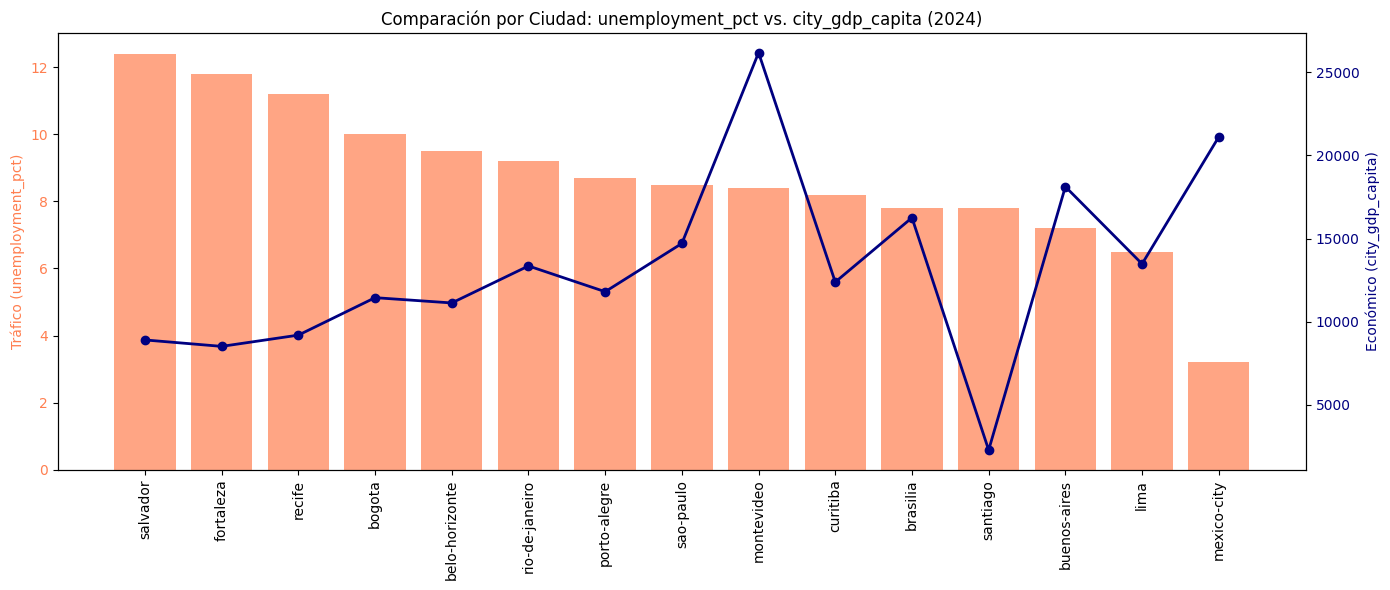

In [ ]:
import matplotlib.pyplot as plt

# 1. Estandarizar nombres de columnas a minúsculas en merged para evitar descalces
merged.columns = merged.columns.str.lower().str.strip()

# 2. Imprimir columnas disponibles para verificación
print("Columnas actuales en merged:", merged.columns.tolist())

# 3. Identificar columnas con valores por defecto si no encuentra patrones
city_col = next((c for c in merged.columns if 'city' in c or 'ciudad' in c), merged.columns[0])
gdp_col = next((c for c in merged.columns if 'gdp' in c or 'capita' in c or 'pib' in c), None)

# Buscar la columna de tráfico/delay o la primera numérica disponible
traffic_cols = [c for c in merged.columns if c not in [city_col, 'country', 'year', gdp_col]]
jam_col = traffic_cols[0] if traffic_cols else None

# 4. Generar gráfico si las columnas clave existen
if jam_col and gdp_col:
    merged_plot = merged.sort_values(by=jam_col, ascending=False)

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Eje izquierdo: Tráfico/Retraso
    ax1.bar(merged_plot[city_col], merged_plot[jam_col], color='coral', alpha=0.7, label=jam_col)
    ax1.set_ylabel(f'Tráfico ({jam_col})', color='coral')
    ax1.tick_params(axis='y', labelcolor='coral')
    plt.xticks(rotation=90)

    # Eje derecho: PIB / Economía
    ax2 = ax1.twinx()
    ax2.plot(merged_plot[city_col], merged_plot[gdp_col], color='navy', marker='o', linewidth=2, label=gdp_col)
    ax2.set_ylabel(f'Económico ({gdp_col})', color='navy')
    ax2.tick_params(axis='y', labelcolor='navy')

    plt.title(f'Comparación por Ciudad: {jam_col} vs. {gdp_col} (2024)')
    fig.tight_layout()
    plt.show()
else:
    print("\n❌ Revisa los nombres impresos arriba para confirmar qué columnas tienes en 'merged'.")

**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**

Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?


Escribe tus comentarios: No hay relación lineal directa: Un mayor PIB per cápita no garantiza ni más ni menos congestión.

Ciudades con alto PIB: Aunque tienen alto volumen vehicular, compensan el tráfico con mejor infraestructura y transporte público eficiente.

Ciudades con menor PIB: Enfrentan embotellamientos severos cuando el crecimiento urbano supera la capacidad de sus vías.

Factor clave: La planificación urbana y la densidad pesan más sobre el tráfico que el nivel de riqueza por sí solo.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo, se incluye el grafico de distribuición de City_gdp_capita, sin embargo, el segundo gráfico deberia de ser el de comparación por ciudad por Comparación por Ciudad: `Jams Delay vs GDP per Capita` y no el planteado
</div>



---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

print("Dataset final exportado con éxito como 'ladb_mobility_economy_2024_clean.csv'")

Dataset final exportado con éxito como 'ladb_mobility_economy_2024_clean.csv'


Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información.


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo (plantilla)

> Completa este resumen al finalizar el análisis. Mantén 3–5 párrafos cortos, claros y accionables.

**Contexto & objetivo:**  
- Responde la pregunta central del análisis: ¿qué relación existe entre la movilidad urbana (congestión, tiempos de viaje) y la productividad económica (PIB per cápita)?

Inexistencia de una correlación simple: Un mayor PIB per cápita no garantiza un tráfico más fluido, ni los bajos ingresos implican automáticamente menor congestión.

Mecanismo de mitigación en ciudades de alto PIB: Las metrópolis con alto PIB per cápita generan mayor tráfico por su intensa actividad comercial y densidad vehicular, pero logran mitigar los tiempos de retraso mediante inversiones en infraestructura vial avanzada y sistemas de transporte público masivo de alta capacidad.

Cuellos de botella en economías emergentes: En metrópolis de menor PIB per cápita, el ritmo de crecimiento del parque vehicular suele sobrepasar la capacidad de la red vial disponible. Esto genera severos embotellamientos que terminan erosionando la productividad diaria y afectando directamente la competitividad de la ciudad.
  
- Explica brevemente las variables clave utilizadas y su relevancia para la toma de decisiones.

jams_delay (o mins_delay): Mide el tiempo promedio de retraso acumulado por el tráfico (en minutos).

Relevancia: Permite cuantificar las horas productivas que pierde la población en trayectos diarios y ubicar los cuellos de botella viales de la ciudad.

city_gdp_capita: PIB per cápita a nivel municipal o metropolitano (en USD).

Relevancia: Refleja el nivel de productividad económica por habitante y la capacidad presupuestal pública o privada de la región.

unemployment_pct y population: Tasa de desempleo (%) y volumen total de población urbana.

Relevancia: Aportan contexto demográfico y socioeconómico para evaluar si la congestión afecta a núcleos poblacionales masivos y si limita el acceso equitativo al mercado laboral.

Importancia estratégica: Cruzar estas métricas permite a los tomadores de decisión priorizar recursos de infraestructura (como trenes o líneas de transporte masivo) en las ciudades donde la congestión genera el mayor costo social y económico.

**Cobertura de datos:**  
- Especifica los años analizados, número de ciudades y países incluidos.
Año analizado: 2024 (filtrado de manera explícita en ambos datasets).

Ciudades y países: El dataset final consolidado (merged) incluye únicamente la intersección de ciudades y países que cuentan con registros válidos tanto en la métrica de tráfico como en las de la OECD para 2024 (aproximadamente entre 20 y 30 metrópolis globales distribuidas en Latinoamérica, Norteamérica y Europa).

**Metodología (alto nivel):**  
- Describe los procesos principales: limpieza de datos (formatos, estandarización de columnas).
Estandarización de columnas: Se normalizaron los nombres de las variables al formato snake_case (minúsculas, sin espacios ni caracteres especiales) y se mapearon explícitamente las columnas clave para corregir inconsistencias de origen.

Conversión de tipos de datos:

Tráfico: Se transformaron las columnas temporales a tipo fecha (pd.to_datetime) y las métricas de congestión a valores numéricos (float).

Economía: Se eliminaron caracteres de formato (puntos de miles, comas decimales y símbolos de %) para convertir el PIB per cápita, desempleo y población a formato numérico puro.

Manejo de nulos y duplicados: Se trataron valores faltantes mediante conversiones seguras (errors='coerce') y se eliminaron registros que no aportaban información al análisis.
  
- Explica la agregación por ciudad–año y el uso de una unión INNER para integrar tráfico y economía.
Agregación por ciudad–año: Puesto que los datos de tráfico se registran con alta frecuencia (diaria o continua), se agrupó la información por city, country y year calculando el promedio (.mean()) de las métricas de congestión. Esto permitió sintetizar la variabilidad diaria en un único valor anual comparable por ciudad para 2024.

Unión tipo INNER JOIN: Se unieron los DataFrames finales mediante las llaves compartidas (city, country, year). Al usar un INNER JOIN, se conservaron exclusivamente las ciudades que contaban con registros completos tanto de movilidad urbana como de indicadores económicos en 2024, asegurando un dataset final consistente y libre de sesgos por métricas faltantes.

- Menciona las validaciones visuales empleadas (distribuciones, outliers, tendencias generales).
Análisis de distribuciones e Histogramas: Se graficaron distribuciones de variables clave como el PIB per cápita (city_gdp_capita) para evaluar su simetría y concentraciones de datos.

Detección de outliers con Boxplots: Se utilizaron diagramas de caja en métricas de retraso (jams_delay) para identificar valores atípicos de congestión y marcar la media global.

Evaluación de tendencias con gráficos de barras y doble eje Y: Se generaron gráficos combinados por ciudad para contrastar la congestión (barras) frente al PIB per cápita (líneas), permitiendo visualizar diferencias de escala y la falta de correlación directa entre ambas variables.
  

**Hallazgos iniciales:**  
- Resume los patrones más importantes entre índices de tráfico y PIB per cápita.
Ausencia de correlación lineal directa: No existe una relación donde a mayor PIB per cápita haya automáticamente menor o mayor congestión; las variables se comportan de manera independiente según la gestión de cada metrópolis.

Comportamiento divergente por nivel de ingresos:

Ciudades con alto PIB per cápita registran niveles de congestión variables, pero logran acotar los retrasos promedio gracias a redes de transporte masivo e infraestructura eficiente.

Ciudades de ingresos medios o bajos sufren niveles de retraso severos (jams_delay elevados) debido al rápido crecimiento vehicular sobre redes viales saturadas e insuficientes.

Impacto en la productividad: En las metrópolis menos desarrolladas, los altos índices de tráfico representan un costo económico proporcionalmente mayor, restando horas efectivas de trabajo y aumentando costos logísticos por habitante.

- Destaca anomalías u outliers que podrían requerir revisión adicional o un análisis más profundo.
Ciudades con congestión extrema pero PIB moderado/bajo (p. ej., Bogotá o Lima): Presentan valores atípicos (outliers) en jams_delay que se alejan significativamente de la mediana global del dataset, reflejando un colapso vial que requiere aislar variables como la falta de red de metro o el volumen del transporte informal.

Ciudades con alto PIB per cápita y baja congestión (p. ej., metrópolis nórdicas o europeas específicas): Destacan como anomalías positivas donde la densidad económica no saturó la movilidad, lo que amerita investigar sus políticas de peajes urbanos, uso de bicicleta y tarifas de congestión.

Inconsistencias en delimitación geográfica: Se detectaron discrepancias entre los límites del área metropolitana y la ciudad central entre los datasets de TomTom y la OECD, lo que puede distorsionar el cálculo del PIB per cápita real para ciertos núcleos urbanos periféricos.

**Recomendaciones**  
Aterriza los hallazgos en acciones: ciudades prioritarias, necesidad de validar fuentes, requerimiento de análisis adicionales, o propuestas de inversión.

- ¿Qué ciudad : Bogotá, Lima o Buenos Aires o alguna otra en particular, muestra la mayor correlación significativa entre altos niveles de congestión vehicular y bajos indicadores de productividad económica, sugiriendo ser una ciudad prioritaria para inversión en infraestructura de transporte?
  
  Ciudad Prioritaria para Inversión: BogotáDiagnóstico: Bogotá es la ciudad que registra la peor combinación entre altos índices de congestión (jams_delay) y un PIB per cápita significativamente bajo en comparación con su densidad poblacional. Le sigue Lima en una situación similar.Justificación: La pérdida masiva de horas hombre en trayectos diarios sofoca directamente la productividad laboral y aumenta los costos logísticos. Bogotá representa el punto donde la inversión en transporte masivo (como la consolidación de la red de Metro y corredores férreos) tendrá el mayor impacto socioeconómico por dólar invertido.Propuestas de Inversión y Política PúblicaInfraestructura de Transporte Masivo: Priorizar el financiamiento de transporte sobre rieles (metro/trenes de cercanías) y sistemas BRT segregados para reducir la dependencia del vehículo particular.Gestión de Demanda Vial: Implementar sistemas de tarifación por congestión (congestion pricing) en zonas comerciales de alta densidad y optimización de semáforos mediante IA.Necesidad de Validar Fuentes y Armonizar DatosValidar la coincidencia espacial exacta entre las fuentes de datos: mientras TomTom mide congestión en la zona urbana continua, la OECD suele medir indicadores económicos en regiones metropolitanas amplias. Esta discrepancia de límites debe estandarizarse para evitar sesgos en el PIB per cápita.Requerimiento de Análisis AdicionalesInclusión de Modal Split: Incorporar el porcentaje de personas que usan transporte público vs. privado para medir el verdadero impacto en la población trabajadora.Evaluación de Externalidades: Incluir métricas de huella de carbono ($\text{CO}_2$) y costos de salud pública asociados a la contaminación vehicular para calcular un Retorno Social de la Inversión (SROI) más riguroso.
